<a href="https://colab.research.google.com/github/zevin69/predictive-maintenance-pump-poc./blob/main/pump_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Maintenance Proof of Concept: Industrial Pump Failures
Early-warning model on real pump sensor data, framed as a pre-sales scenario
for a simulated UAE water utility (120 pumps).

## Step 1: Loading the data
220,320 one-minute readings from an industrial pump system (April–August 2018), 52 sensors, and a machine status label.

In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv('sensor.csv')

print(df.shape)
print(df.head())
print(df['machine_status'].value_counts())


Saving sensor.csv to sensor (1).csv
(220320, 55)
   Unnamed: 0            timestamp  sensor_00  sensor_01  sensor_02  \
0           0  2018-04-01 00:00:00   2.465394   47.09201    53.2118   
1           1  2018-04-01 00:01:00   2.465394   47.09201    53.2118   
2           2  2018-04-01 00:02:00   2.444734   47.35243    53.2118   
3           3  2018-04-01 00:03:00   2.460474   47.09201    53.1684   
4           4  2018-04-01 00:04:00   2.445718   47.13541    53.2118   

   sensor_03  sensor_04  sensor_05  sensor_06  sensor_07  ...  sensor_43  \
0  46.310760   634.3750   76.45975   13.41146   16.13136  ...   41.92708   
1  46.310760   634.3750   76.45975   13.41146   16.13136  ...   41.92708   
2  46.397570   638.8889   73.54598   13.32465   16.03733  ...   41.66666   
3  46.397568   628.1250   76.98898   13.31742   16.24711  ...   40.88541   
4  46.397568   636.4583   76.58897   13.35359   16.21094  ...   41.40625   

   sensor_44  sensor_45  sensor_46  sensor_47  sensor_48  sensor_49

## Step 2: Exploring the data
Cleaning the table and looking at how sensors behave around the 7 failures.

In [ ]:
df = df.drop(columns=['Unnamed: 0'])

df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp')

missing = df.isnull().mean().sort_values(ascending=False)
print(missing.head(10).round(1))

sensor_15    1.0
sensor_50    0.3
sensor_51    0.1
sensor_00    0.0
sensor_07    0.0
sensor_08    0.0
sensor_06    0.0
sensor_09    0.0
sensor_01    0.0
sensor_30    0.0
dtype: float64


### Removing the empty sensor and finding the failures
sensor_15 has no data, so it is dropped.

In [ ]:
df = df.drop(columns = ['sensor_15'])

broken = df[df['machine_status'] == 'BROKEN']
print(broken.index)

DatetimeIndex(['2018-04-12 21:55:00', '2018-04-18 00:30:00',
               '2018-05-19 03:18:00', '2018-05-25 00:30:00',
               '2018-06-28 22:00:00', '2018-07-08 00:11:00',
               '2018-07-25 14:00:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)


### Sensor 04 over 5 months (red = failure)

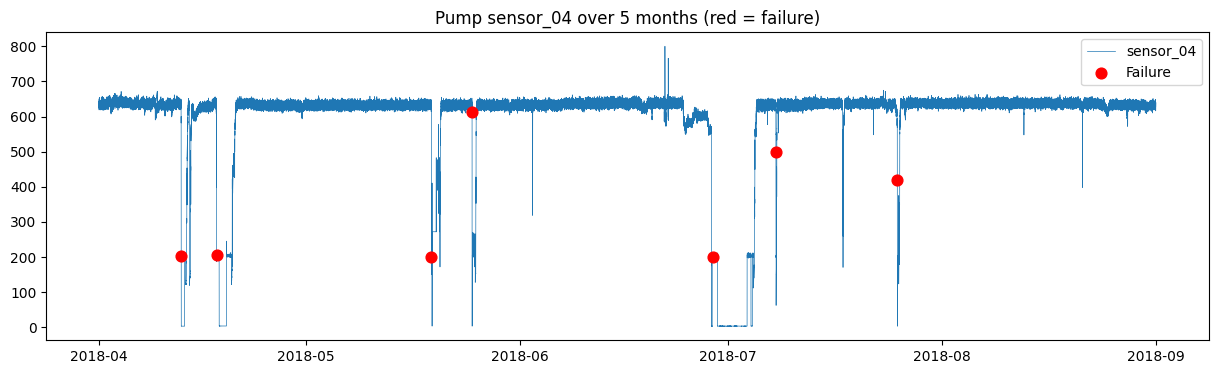

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))
plt.plot(df.index, df['sensor_04'], linewidth=0.5, label='sensor_04')
plt.scatter(broken.index, broken['sensor_04'], color='red', s=60, zorder=5, label='Failure')
plt.title('Pump sensor_04 over 5 months (red = failure)')
plt.legend()
plt.show()

### Comparing multiple sensors
Some sensors react clearly to failures. Others have faults (sensor_51 is stuck at 1000 for about 10 days).

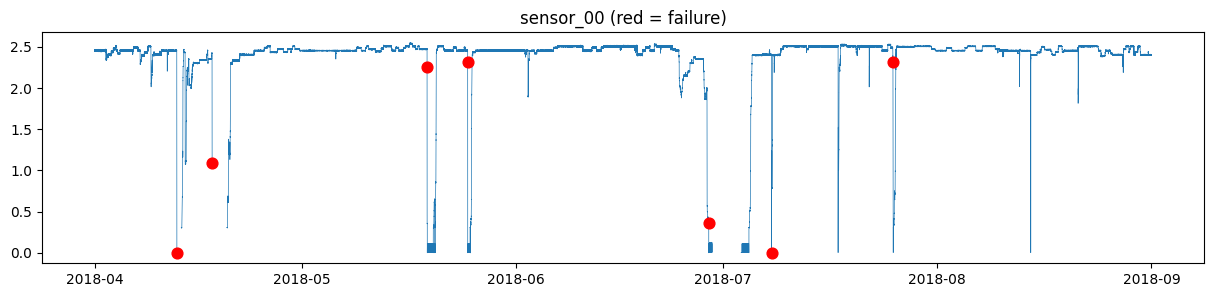

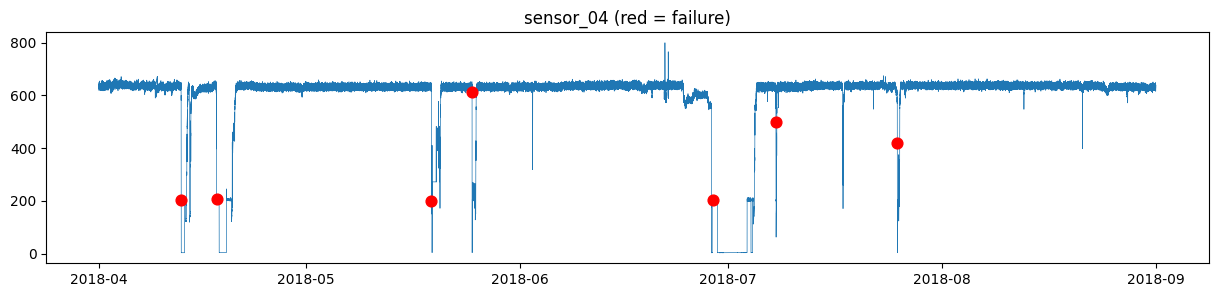

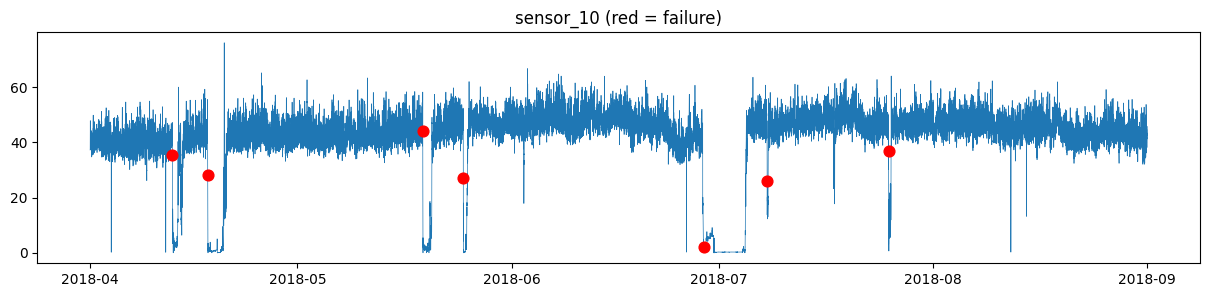

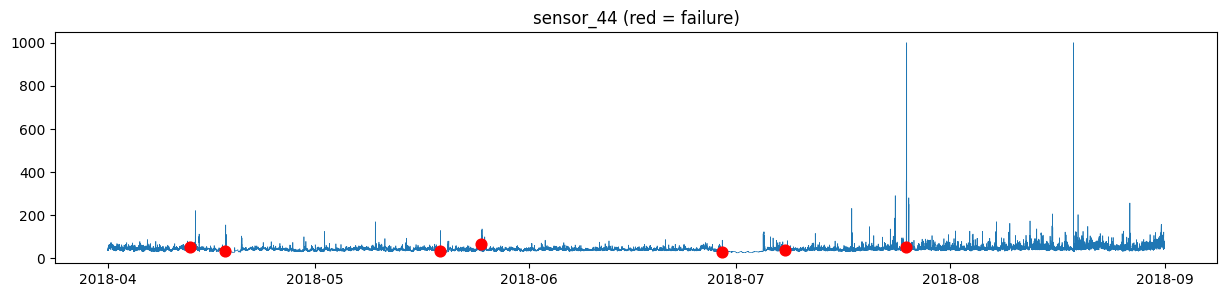

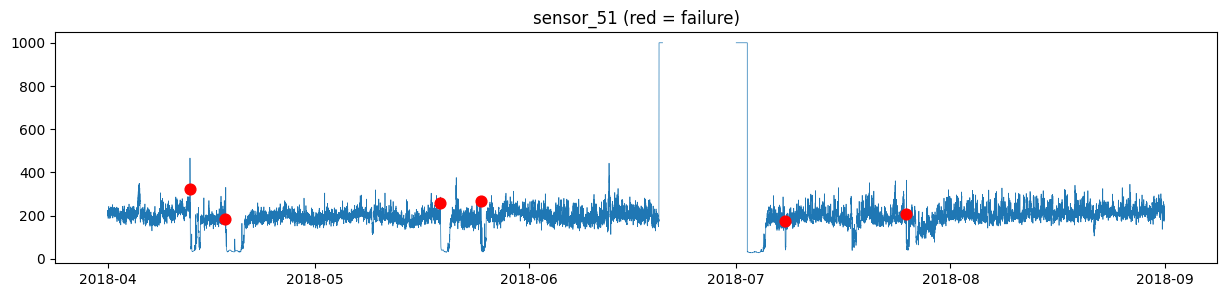

In [ ]:
sensors_to_check = ['sensor_00', 'sensor_04', 'sensor_10', 'sensor_44', 'sensor_51']

for s in sensors_to_check:
    plt.figure(figsize=(15, 3))
    plt.plot(df.index, df[s], linewidth=0.5)
    plt.scatter(broken.index, broken[s], color='red', s=60, zorder=5)
    plt.title(f'{s} (red = failure)')
    plt.show()


## Step 3: Labelling a 24-hour warning zone
With only 7 failures, the 24 hours before each failure are labelled as "warning", which gives the model thousands of examples to learn from.

In [10]:
df['warning'] = 0

for t in broken.index:
    start = t - pd.Timedelta(hours=24)
    df.loc[(df.index >= start) & (df.index < t), 'warning'] = 1

print(df['warning'].value_counts())


warning
0    210240
1     10080
Name: count, dtype: int64


### Zooming in on each failure
Only 2 of the 7 failures show a clear early drift on sensor_04. The rest look sudden on this sensor.

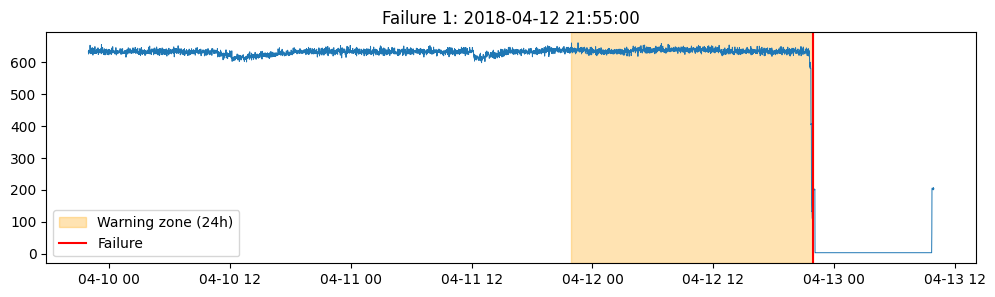

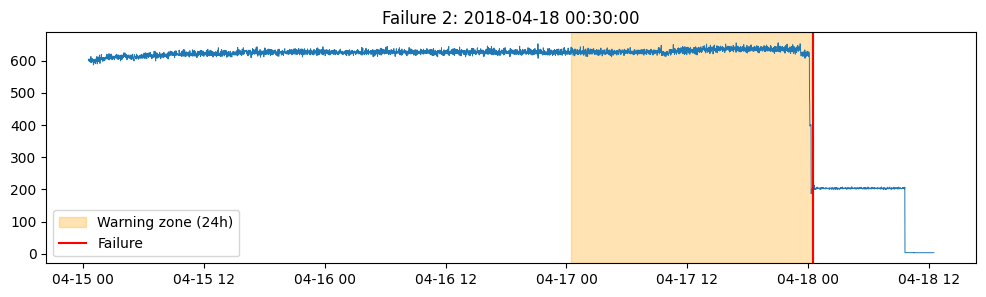

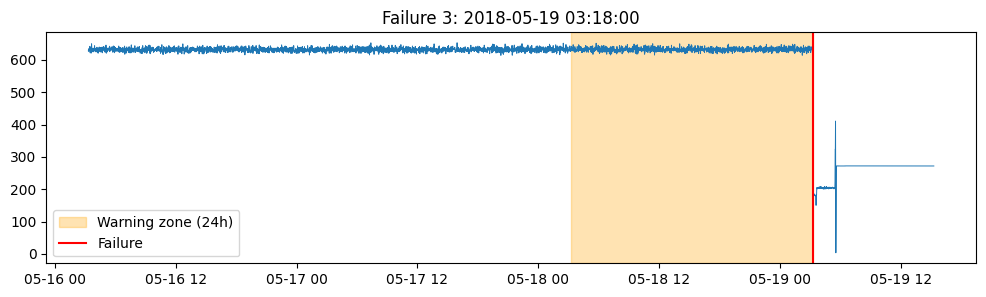

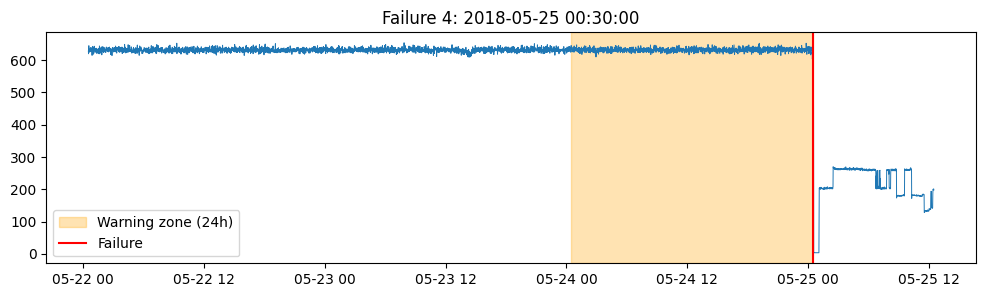

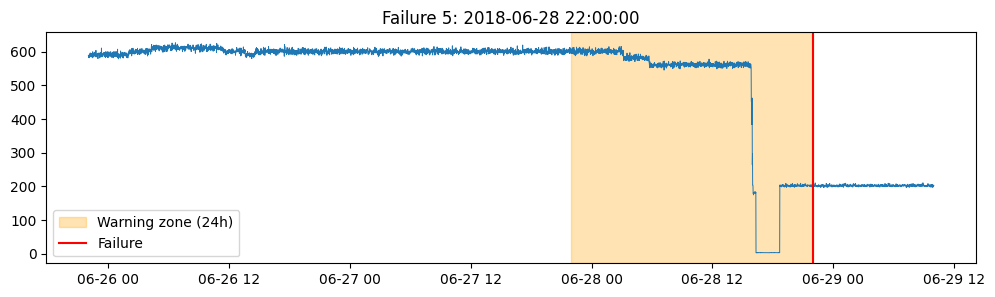

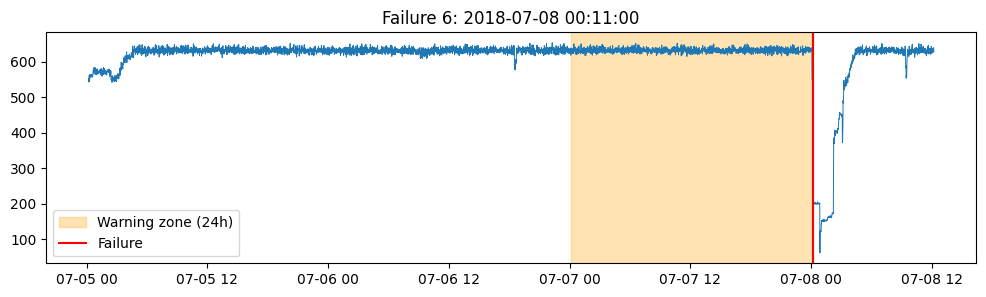

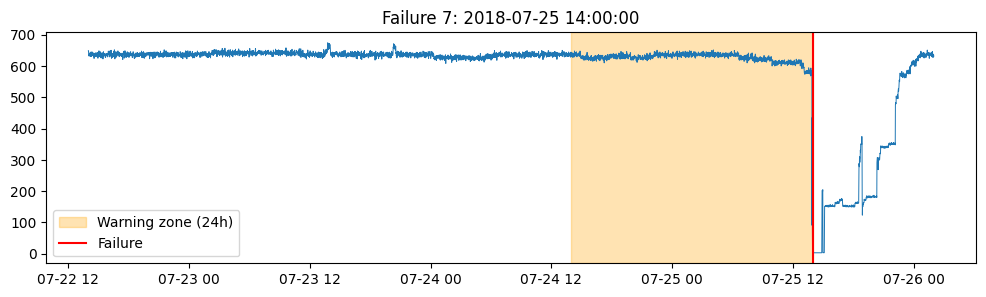

In [11]:
for i, t in enumerate(broken.index):
    window = df.loc[t - pd.Timedelta(days=3) : t + pd.Timedelta(hours=12)]

    plt.figure(figsize=(12, 3))
    plt.plot(window.index, window['sensor_04'], linewidth=0.7)
    plt.axvspan(t - pd.Timedelta(hours=24), t, color='orange', alpha=0.3, label='Warning zone (24h)')
    plt.axvline(t, color='red', label='Failure')
    plt.title(f'Failure {i+1}: {t}')
    plt.legend()
    plt.show()

## Step 4: Baseline model (raw sensor values)
Keep only minutes when the pump is running normally, split by date (train: April–June, test: July–August), and train a Random Forest.

In [12]:
df = df.ffill()

clean = df[(df['machine_status'] == 'NORMAL') & (df['sensor_04'] > 400)].copy()

clean = clean.drop(columns=['sensor_50'])
clean = clean.bfill()

print(clean.shape)
print(clean['warning'].value_counts())


(203405, 52)
warning
0    193718
1      9687
Name: count, dtype: int64


### Time-based train/test split

In [13]:
sensor_cols = [c for c in clean.columns if c.startswith('sensor_')]

train = clean[clean.index <  '2018-07-01']
test  = clean[clean.index >= '2018-07-01']

X_train, y_train = train[sensor_cols], train['warning']
X_test,  y_test  = test[sensor_cols],  test['warning']

print('Train:', X_train.shape, '| warning minutes:', y_train.sum())
print('Test: ', X_test.shape,  '| warning minutes:', y_test.sum())


Train: (120525, 50) | warning minutes: 6812
Test:  (82880, 50) | warning minutes: 2875


### Training the model

In [14]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=50,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)
model.fit(X_train, y_train)
print('Training done!')


Training done!


### Risk score on unseen data


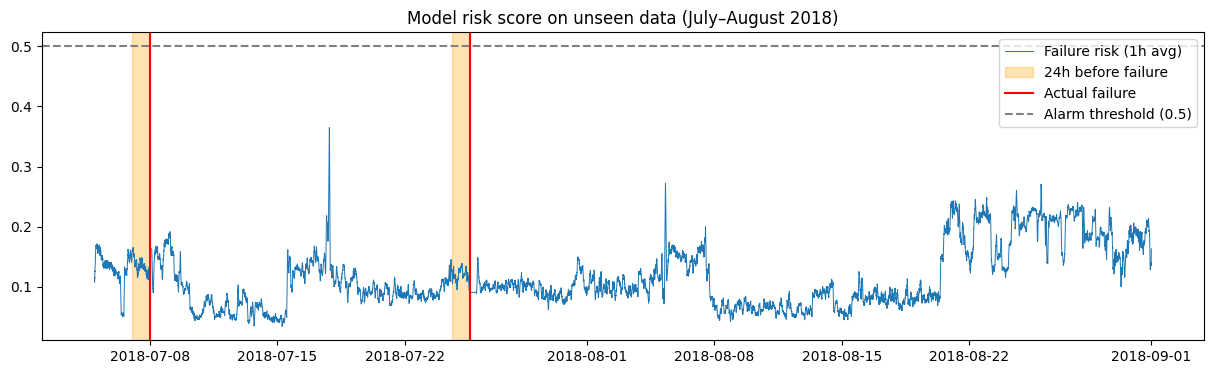

In [15]:
test = test.copy()
test['risk'] = model.predict_proba(X_test)[:, 1]
test['risk_smooth'] = test['risk'].rolling(60, min_periods=1).mean()  # 1hour average

plt.figure(figsize=(15, 4))
plt.plot(test.index, test['risk_smooth'], linewidth=0.7, label='Failure risk (1h avg)')

future_failures = broken.index[broken.index >= '2018-07-01']
for i, t in enumerate(future_failures):
    plt.axvspan(t - pd.Timedelta(hours=24), t, color='orange', alpha=0.3,
                label='24h before failure' if i == 0 else None)
    plt.axvline(t, color='red', label='Actual failure' if i == 0 else None)

plt.axhline(0.5, color='gray', linestyle='--', label='Alarm threshold (0.5)')
plt.title('Model risk score on unseen data (July–August 2018)')
plt.legend()
plt.show()

### Results
97% accuracy but 0 failures caught: the model predicted "normal" every time. Accuracy is misleading for rare failures.

In [16]:
from sklearn.metrics import classification_report

test['alarm'] = (test['risk_smooth'] > 0.5).astype(int)
print(classification_report(y_test, test['alarm'], target_names=['Normal', 'Warning']))

importance = pd.Series(model.feature_importances_, index=sensor_cols).sort_values(ascending=False)
print('\nTop 10 most useful sensors:')
print(importance.head(10).round(3))

              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98     80005
     Warning       0.00      0.00      0.00      2875

    accuracy                           0.97     82880
   macro avg       0.48      0.50      0.49     82880
weighted avg       0.93      0.97      0.95     82880


Top 10 most useful sensors:
sensor_28    0.145
sensor_36    0.096
sensor_25    0.089
sensor_26    0.062
sensor_00    0.060
sensor_27    0.039
sensor_31    0.036
sensor_34    0.035
sensor_23    0.032
sensor_35    0.031
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Step 5: Change features
Instead of raw values, each sensor is described by how unusual its last hour is compared with its last 24 hours, and how noisy it is.

In [17]:
sensors = [c for c in df.columns if c.startswith('sensor_') and c != 'sensor_50']
s = df[sensors].astype('float32')

mean_1h  = s.rolling('60min').mean()
mean_24h = s.rolling('24h').mean()
std_1h   = s.rolling('60min').std()
std_24h  = s.rolling('24h').std()

unusual = ((mean_1h - mean_24h) / (std_24h + 1e-6)).add_suffix('_unusual')
noise   = std_1h.add_suffix('_noise')

feat = pd.concat([unusual, noise], axis=1).fillna(0)
feat['warning'] = df['warning']

mask = (df['machine_status'] == 'NORMAL') & (df['sensor_04'] > 400)
feat = feat[mask]

print(feat.shape)

(203405, 101)


### Training Model 2


In [18]:
feature_cols = [c for c in feat.columns if c != 'warning']

train = feat[feat.index <  '2018-07-01']
test  = feat[feat.index >= '2018-07-01'].copy()

model2 = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_leaf=50,
    class_weight='balanced', n_jobs=-1, random_state=42
)
model2.fit(train[feature_cols], train['warning'])

test['risk'] = model2.predict_proba(test[feature_cols])[:, 1]
test['risk_smooth'] = test['risk'].rolling(60, min_periods=1).mean()
print('Training done!')

Training done!


### Model 2 risk score on unseen data

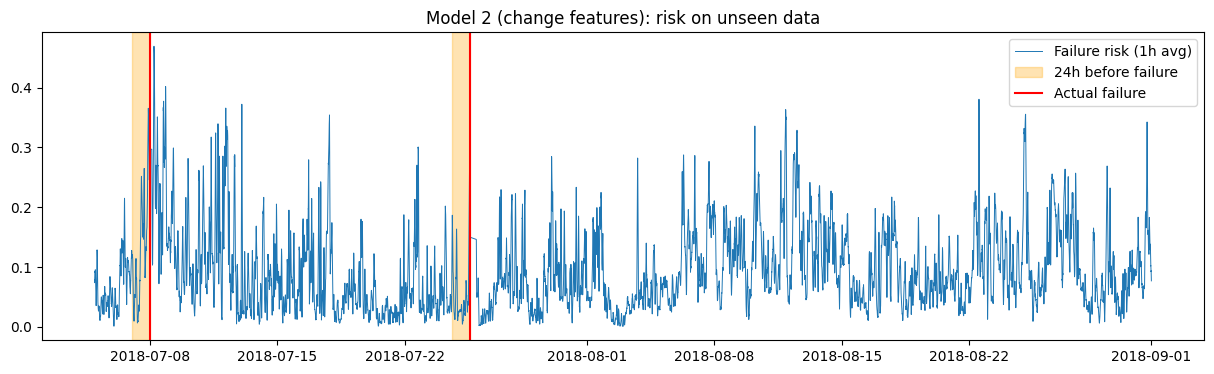

In [19]:
plt.figure(figsize=(15, 4))
plt.plot(test.index, test['risk_smooth'], linewidth=0.7, label='Failure risk (1h avg)')
for i, t in enumerate(future_failures):
    plt.axvspan(t - pd.Timedelta(hours=24), t, color='orange', alpha=0.3,
                label='24h before failure' if i == 0 else None)
    plt.axvline(t, color='red', label='Actual failure' if i == 0 else None)
plt.title('Model 2 (change features): risk on unseen data')
plt.legend()
plt.show()

### Failures caught vs. false alarms at different thresholds
At threshold 0.3: 1 of 2 failures caught about 3 hours ahead, but 13 false-alarm days.


In [20]:
def evaluate(threshold):
    caught, lead_hours = 0, []
    for t in future_failures:
        zone = test.loc[t - pd.Timedelta(hours=24) : t]
        hits = zone.index[zone['risk_smooth'] > threshold]
        if len(hits) > 0:
            caught += 1
            lead_hours.append(round((t - hits[0]).total_seconds() / 3600, 1))
    outside = (test[test['warning'] == 0]['risk_smooth'] > threshold).astype(int)
    false_alarm_days = int(outside.resample('1D').max().sum())
    return caught, lead_hours, false_alarm_days

print('Threshold | Failures caught (of 2) | Hours of warning | False-alarm days')
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    c, lead, fa = evaluate(th)
    print(f'   {th}    |          {c}             | {lead} | {fa}')

importance2 = pd.Series(model2.feature_importances_, index=feature_cols).sort_values(ascending=False)
print('\nTop 10 features:')
print(importance2.head(10).round(3))

Threshold | Failures caught (of 2) | Hours of warning | False-alarm days
   0.1    |          2             | [24.0, 24.0] | 55
   0.2    |          2             | [12.0, 1.4] | 35
   0.3    |          1             | [2.9] | 13
   0.4    |          0             | [] | 1
   0.5    |          0             | [] | 0
   0.6    |          0             | [] | 0

Top 10 features:
sensor_34_noise      0.062
sensor_00_unusual    0.060
sensor_36_unusual    0.056
sensor_13_noise      0.051
sensor_35_noise      0.036
sensor_36_noise      0.031
sensor_00_noise      0.031
sensor_26_unusual    0.027
sensor_02_unusual    0.023
sensor_08_unusual    0.023
dtype: float64


## Step 6: Alarm logic to reduce false alarms
Two rules: the risk must stay high for a minimum hold time, and alarms are ignored for 24 hours after a repair.
Chosen setting: threshold 0.3 with a 1-hour hold, which gives 1 of 2 failures caught about 2 hours ahead with 4 false-alarm days in 59.

In [21]:
def evaluate2(threshold, hold_hours=2, grace_hours=24):
    r = test['risk_smooth']

    alarm = (r > threshold).astype(float).rolling(f'{hold_hours}h').min() == 1

    for t in future_failures:
        after = test.index[test.index > t]
        if len(after) > 0:
            restart = after[0]
            alarm[(alarm.index >= restart) & (alarm.index < restart + pd.Timedelta(hours=grace_hours))] = False

    caught, lead_hours = 0, []
    for t in future_failures:
        zone = alarm.loc[t - pd.Timedelta(hours=24) : t]
        hits = zone.index[zone]
        if len(hits) > 0:
            caught += 1
            lead_hours.append(round((t - hits[0]).total_seconds() / 3600, 1))

    outside = alarm[test['warning'] == 0].astype(int)
    false_alarm_days = int(outside.resample('1D').max().sum())
    return caught, lead_hours, false_alarm_days

print('Days in test period:', test.index.normalize().nunique())
print('\nThreshold | Hold | Caught | Hours of warning | False-alarm days')
for th in [0.15, 0.2, 0.25, 0.3]:
    for hold in [1, 2, 3]:
        c, lead, fa = evaluate2(th, hold)
        print(f'   {th:<5}  |  {hold}h  |  {c}/2   | {lead} | {fa}')

Days in test period: 59

Threshold | Hold | Caught | Hours of warning | False-alarm days
   0.15   |  1h  |  2/2   | [11.4, 0.6] | 37
   0.15   |  2h  |  1/2   | [10.4] | 23
   0.15   |  3h  |  1/2   | [1.8] | 17
   0.2    |  1h  |  2/2   | [11.0, 0.4] | 20
   0.2    |  2h  |  1/2   | [1.6] | 9
   0.2    |  3h  |  1/2   | [0.6] | 4
   0.25   |  1h  |  1/2   | [2.3] | 9
   0.25   |  2h  |  1/2   | [1.3] | 5
   0.25   |  3h  |  0/2   | [] | 2
   0.3    |  1h  |  1/2   | [1.9] | 4
   0.3    |  2h  |  0/2   | [] | 1
   0.3    |  3h  |  0/2   | [] | 0


## Results log
- Data: 7 failures in ~5 months, ~10 days downtime
- Model 1 (raw sensor values): 97% accuracy but caught 0/2 failures
- Model 2 (change features): caught 1/2 at threshold 0.3, ~3h warning, 13 false-alarm days
- Key insight: failure 6 looked sudden on sensor_04, but the model caught it using other sensors
- Step 6 (hold time + grace period): threshold 0.3 + 1h hold → 1/2 caught, ~2h warning, 4 false-alarm days in 59
- "Catch-all" setting (0.2 / 1h): 2/2 caught but 20 false-alarm days, and one catch was only 24 min early
